# 02. Correlação e matriz de confusão

Este caderno responde a uma pergunta simples: **o que aconteceu no exterior de madrugada ajuda a prever a abertura da B3?**

Os alvos são o **WIN** (mini índice Bovespa) e o **WDO** (mini dólar). São contratos futuros: acordos de compra e venda para uma data futura, negociados em bolsa. Usamos duas medidas da madrugada: o *gap* (salto de preço na abertura) e o comportamento do preço na hora seguinte.

Aqui é a **primeira avaliação**. Só linha de base e regressão logística.

## 1. Ambiente e parâmetros

In [1]:
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/assets.yaml").is_file())

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from IPython.display import display, Markdown
from abertura.clean import roll_dates, gap_event_study
from abertura.models import (CLASSES, add_aligned_features, baseline_model, logistic_model,
                             walk_forward_predict, scores, confusion)
from abertura.sessions import b3_sessions

pd.set_option("display.max_columns", 12)
SURFACE, INK, MUTED = "#fcfcfb", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
                     "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED})
FIGURES = ROOT / "reports/figures"
FIGURES.mkdir(parents=True, exist_ok=True)

params = yaml.safe_load((ROOT / "config/params.yaml").read_text())
WF = {k: params["walk_forward"][k] for k in ("train_years", "test_months", "step_months", "min_train_rows")}
LOGISTIC_C = params["models"]["logistic_c"]
GAP_K = params["labels"]["gap_threshold"]["value"]
TREND_MARGIN = params["labels"]["behavior"]["trend_margin"]
WINDOW = params["labels"]["post_open_minutes"]

TARGETS = ["win", "wdo"]
NAMES = {"win": "WIN", "wdo": "WDO"}
EXTERNAL = [key for key, asset in yaml.safe_load((ROOT / "config/assets.yaml").read_text())["assets"].items()
            if asset["source"] == "dukascopy"]
OVERNIGHT = [f"x_pre_{a}_overnight" for a in EXTERNAL]
LABELS = {"tendencia": "tendência", "reversao": "reversão", "lateral": "lateral",
          "alta": "alta", "baixa": "baixa", "normal": "normal"}

calendar = b3_sessions("2020-09-01", "2026-10-30").index
daily = pd.read_parquet(ROOT / "data/processed/daily.parquet")
display(Markdown(
    f"Treino em janela móvel de **{WF['train_years']} anos**, teste nos **{WF['test_months']} meses** seguintes, "
    f"avanço de **{WF['step_months']} meses**, mínimo de **{WF['min_train_rows']}** linhas de treino. "
    f"Regressão logística com regularização C = **{LOGISTIC_C}**. "
    f"Limiar de gap: **{GAP_K:.1%}**. Janela pós-abertura: **{WINDOW} min**."))

Treino em janela móvel de **2 anos**, teste nos **3 meses** seguintes, avanço de **3 meses**, mínimo de **60** linhas de treino. Regressão logística com regularização C = **0.1**. Limiar de gap: **0.3%**. Janela pós-abertura: **60 min**.

## 2. Rolagem: o gap falso

Um contrato futuro **vence** numa data fixa. Perto do vencimento, o mercado passa a negociar o contrato seguinte, com outro preço. A série contínua do MetaTrader (`WIN$N`, `WDO$N`) **emenda um contrato no outro sem ajustar o preço**. Isso é a *rolagem*.

O efeito: entre o último candle de um contrato e o primeiro do outro, o preço "salta" só porque os contratos são diferentes. É um **gap falso**, que não é uma notícia nem uma reação do mercado.

A tabela abaixo é um *estudo de evento*. Para cada data de rolagem, olhamos o gap bruto (abertura do dia dividida pelo último fechamento do pregão anterior, menos 1) nos 3 pregões antes e depois. O `offset` 0 é o dia da rolagem. Se a rolagem cria um gap falso, ele aparece só no offset 0.

- `n`: quantas rolagens têm gap calculável nesse offset.
- `media_pct`: média do gap, em %.
- `positivos_pct`: % das rolagens com gap positivo.

In [2]:
event = {}
for asset in TARGETS:
    candles = pd.read_parquet(ROOT / f"data/interim/{asset}_m1.parquet")
    rolls = roll_dates(asset, calendar)
    event[asset] = (len(rolls), gap_event_study(candles, calendar, rolls, span=3))
    display(Markdown(f"### {NAMES[asset]}: {len(rolls)} datas de rolagem no calendário"))
    display(event[asset][1].round(3))
del candles

### WIN: 37 datas de rolagem no calendário

,offset,n,media_pct,positivos_pct
0,-3,32,0.062,62.500
1,-2,32,-0.039,56.250
2,-1,32,-0.042,56.250
3,0,33,1.626,100.000
4,1,33,0.021,66.667
5,2,34,-0.087,41.176
6,3,34,-0.166,47.059


### WDO: 74 datas de rolagem no calendário

,offset,n,media_pct,positivos_pct
0,-3,62,-0.030,38.710
1,-2,62,-0.022,45.161
2,-1,62,-0.004,53.226
3,0,62,0.441,87.097
4,1,63,-0.156,31.746
5,2,62,-0.040,41.935
6,3,62,-0.046,41.935


In [3]:
roll0 = {a: event[a][1].set_index("offset").loc[0] for a in TARGETS}
roll_other = {a: event[a][1].query("offset != 0").media_pct.abs().max() for a in TARGETS}
valid_gap_on_roll = int(daily[daily.is_roll_day].x_open_gap.notna().sum())
n_roll_days = int(daily.is_roll_day.sum())
display(Markdown(
    f"No **WIN**, o gap médio no dia da rolagem é de **{roll0['win'].media_pct:.2f}%**, positivo em "
    f"**{roll0['win'].positivos_pct:.0f}%** dos {int(roll0['win'].n)} casos. Nos outros dias, a média nunca passa de "
    f"{roll_other['win']:.2f}% em módulo. "
    f"No **WDO**, o gap médio no dia da rolagem é de **{roll0['wdo'].media_pct:.2f}%**, positivo em "
    f"**{roll0['wdo'].positivos_pct:.0f}%** dos {int(roll0['wdo'].n)} casos. Nos outros dias, a média nunca passa de "
    f"{roll_other['wdo']:.2f}% em módulo.\n\n"
    "No WIN, a troca cai no **vencimento** (quarta-feira mais próxima do dia 15 dos meses pares). "
    "No WDO, a troca cai no **último pregão do mês**.\n\n"
    f"Por isso a tabela diária marca esses dias com `is_roll_day` e deixa o gap **sem valor**. "
    f"Há {n_roll_days} dias de rolagem na tabela (WIN e WDO juntos) e {valid_gap_on_roll} deles têm gap válido."))

No **WIN**, o gap médio no dia da rolagem é de **1.63%**, positivo em **100%** dos 33 casos. Nos outros dias, a média nunca passa de 0.17% em módulo. No **WDO**, o gap médio no dia da rolagem é de **0.44%**, positivo em **87%** dos 62 casos. Nos outros dias, a média nunca passa de 0.16% em módulo.

No WIN, a troca cai no **vencimento** (quarta-feira mais próxima do dia 15 dos meses pares). No WDO, a troca cai no **último pregão do mês**.

Por isso a tabela diária marca esses dias com `is_roll_day` e deixa o gap **sem valor**. Há 96 dias de rolagem na tabela (WIN e WDO juntos) e 0 deles têm gap válido.

## 3. A tabela diária

Cada linha é **um pregão de um alvo** (WIN ou WDO). As colunas são de três tipos:

- `x_pre_*`: variáveis medidas **até as 08:58 de Brasília**, antes da abertura (retorno overnight, ou seja, da noite, de cada ativo externo etc.).
- `x_open_*`: variáveis que dependem da abertura, como o próprio gap.
- `y_*`: rótulos, isto é, o que queremos prever. Usam dados do futuro e nunca entram como variável.

**Rótulos usados**

- `y_gap_class` (tipo de abertura): compara a abertura com o fechamento do dia anterior. **Alta** se subiu mais que o limiar, **baixa** se caiu mais que o limiar, **normal** nos demais casos.
- `y_behavior` (comportamento): só existe em dias de gap relevante (alta ou baixa). Olha a primeira hora do pregão:
  - **reversão**: o preço volta a tocar o fechamento do dia anterior, ou seja, o gap "fecha";
  - **tendência**: a janela termina mais longe da abertura, na direção do gap, por uma margem mínima;
  - **lateral**: nem uma coisa nem outra.

In [4]:
display(Markdown(
    f"O limiar do gap é **{GAP_K:.1%}** (acima de +{GAP_K:.1%} é alta, abaixo de -{GAP_K:.1%} é baixa). "
    f"A janela é de **{WINDOW} minutos**. Na tendência, a janela fecha mais de **{TREND_MARGIN:.1%}** além da abertura, "
    "na direção do gap."))
summary = daily.groupby("asset").agg(
    linhas=("date_brt", "size"), elegiveis=("is_eligible", "sum"), dias_de_rolagem=("is_roll_day", "sum"),
    gaps_validos=("x_open_gap", "count")).loc[TARGETS]
summary.index = [NAMES[a] for a in summary.index]
display(summary)
classes = {}
for key, order in (("y_gap_class", CLASSES["y_gap_class"]), ("y_behavior", CLASSES["y_behavior"])):
    counts = daily.groupby("asset")[key].value_counts().unstack().reindex(columns=order).loc[TARGETS]
    share = counts.div(counts.sum(axis=1), axis=0).mul(100).round(1)
    classes[key] = (counts, share)
    shown = counts.astype(int).astype(str) + " (" + share.astype(str) + "%)"
    shown.index = [NAMES[a] for a in shown.index]
    shown.columns = [LABELS[c] for c in shown.columns]
    display(Markdown(f"**Distribuição de `{key}`** (contagem e % dos dias com rótulo)"))
    display(shown)

O limiar do gap é **0.3%** (acima de +0.3% é alta, abaixo de -0.3% é baixa). A janela é de **60 minutos**. Na tendência, a janela fecha mais de **0.1%** além da abertura, na direção do gap.

,linhas,elegiveis,dias_de_rolagem,gaps_validos
WIN,1368,1351,33,1321
WDO,1288,1272,63,1209


**Distribuição de `y_gap_class`** (contagem e % dos dias com rótulo)

,baixa,normal,alta
WIN,280 (21.2%),733 (55.5%),308 (23.3%)
WDO,200 (16.5%),826 (68.3%),183 (15.1%)


**Distribuição de `y_behavior`** (contagem e % dos dias com rótulo)

,tendência,reversão,lateral
WIN,240 (40.8%),121 (20.6%),227 (38.6%)
WDO,130 (33.9%),96 (25.1%),157 (41.0%)


In [5]:
g_share, b_share = classes["y_gap_class"][1], classes["y_behavior"][1]
display(Markdown(
    f"No WIN, {g_share.loc['win','alta']:.0f}% dos dias abrem em alta, {g_share.loc['win','baixa']:.0f}% em baixa e "
    f"{g_share.loc['win','normal']:.0f}% normal. No WDO: {g_share.loc['wdo','alta']:.0f}% alta, "
    f"{g_share.loc['wdo','baixa']:.0f}% baixa e {g_share.loc['wdo','normal']:.0f}% normal.\n\n"
    f"Nos dias de gap relevante, o WIN tem {b_share.loc['win','tendencia']:.0f}% de tendência, "
    f"{b_share.loc['win','reversao']:.0f}% de reversão e {b_share.loc['win','lateral']:.0f}% lateral. "
    f"O WDO tem {b_share.loc['wdo','tendencia']:.0f}%, {b_share.loc['wdo','reversao']:.0f}% e "
    f"{b_share.loc['wdo','lateral']:.0f}%."))

No WIN, 23% dos dias abrem em alta, 21% em baixa e 56% normal. No WDO: 15% alta, 16% baixa e 68% normal.

Nos dias de gap relevante, o WIN tem 41% de tendência, 21% de reversão e 39% lateral. O WDO tem 34%, 25% e 41%.

## 4. Correlação com o gap

A **correlação de Pearson** mede quanto duas séries andam juntas. Vai de -1 a +1:

- perto de +1: quando uma sobe, a outra tende a subir;
- perto de -1: quando uma sobe, a outra tende a cair;
- perto de 0: não há relação linear.

Aqui comparamos o retorno **overnight** de cada ativo externo (do fechamento da B3 no dia anterior até 08:58) com o **gap** do WIN e do WDO. Só entram pregões elegíveis com os dois valores presentes.

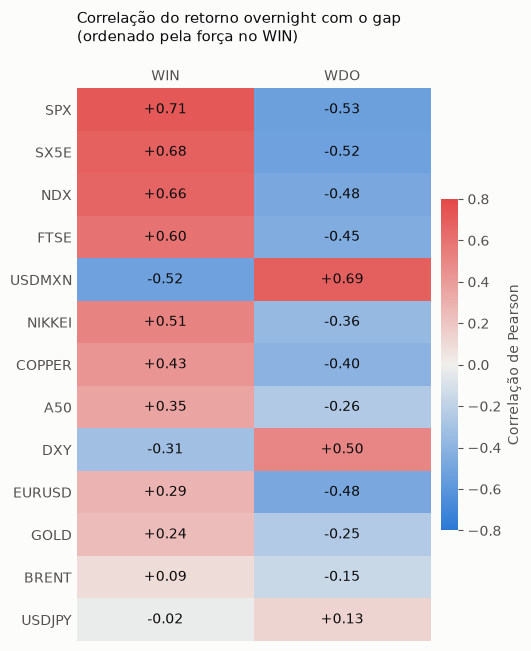

In [6]:
BLUE, RED, NEUTRAL = "#2a78d6", "#e34948", "#f0efec"
DIVERGING = LinearSegmentedColormap.from_list("div", [BLUE, NEUTRAL, RED])
SEQUENTIAL = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

def ink_on(rgba) -> str:
    """Texto branco em células escuras e preto nas claras."""
    r, g, b = rgba[:3]
    return "white" if 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.45 else INK

tables = {a: daily[(daily.asset == a) & daily.is_eligible].set_index("date_brt").sort_index() for a in TARGETS}
corr = pd.DataFrame({NAMES[a]: tables[a][OVERNIGHT].corrwith(tables[a].x_open_gap) for a in TARGETS})
corr.index = EXTERNAL
corr = corr.reindex(corr["WIN"].abs().sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(5.2, 6.4), constrained_layout=True)
limit = np.ceil(corr.abs().to_numpy().max() * 10) / 10
image = ax.imshow(corr.to_numpy(), cmap=DIVERGING, vmin=-limit, vmax=limit, aspect="auto")
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        ax.text(j, i, f"{corr.iloc[i, j]:+.2f}", ha="center", va="center", fontsize=10,
                color=ink_on(image.cmap(image.norm(corr.iloc[i, j]))))
ax.set_xticks(range(2), corr.columns)
ax.set_yticks(range(len(corr)), [a.upper() for a in corr.index])
ax.xaxis.tick_top()
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title("Correlação do retorno overnight com o gap\n(ordenado pela força no WIN)", fontsize=11, pad=34, loc="left")
bar = fig.colorbar(image, ax=ax, shrink=0.6, pad=0.03)
bar.set_label("Correlação de Pearson")
bar.outline.set_visible(False)
fig.savefig(FIGURES / "05_correlacoes.png", dpi=150)
plt.show()

In [7]:
n_pairs = {NAMES[a]: int(tables[a][OVERNIGHT + ["x_open_gap"]].dropna(subset=["x_open_gap"]).shape[0]) for a in TARGETS}
top = {c: corr[c].abs().idxmax() for c in corr.columns}
display(Markdown(
    f"A maior correlação com o gap do WIN é a de **{top['WIN'].upper()}** ({corr.loc[top['WIN'], 'WIN']:+.2f}). "
    f"Para o WDO, a maior é a de **{top['WDO'].upper()}** ({corr.loc[top['WDO'], 'WDO']:+.2f}). "
    f"A correlação mais fraca do WIN é {corr['WIN'].abs().min():.2f} em módulo.\n\n"
    "**Correlação não é previsão.** Ela mede o que anda junto no mesmo dia, sobre todos os dados de uma vez, "
    "inclusive o futuro de cada janela. Prever exige treinar no passado e testar no futuro. É o que vem a seguir."))

A maior correlação com o gap do WIN é a de **SPX** (+0.71). Para o WDO, a maior é a de **USDMXN** (+0.69). A correlação mais fraca do WIN é 0.02 em módulo.

**Correlação não é previsão.** Ela mede o que anda junto no mesmo dia, sobre todos os dados de uma vez, inclusive o futuro de cada janela. Prever exige treinar no passado e testar no futuro. É o que vem a seguir.

## 5. Pergunta 1: que tipo de abertura vai ser? (`y_gap_class`)

O modelo escolhe entre **alta**, **baixa** e **normal**, com uma probabilidade para cada uma. Três configurações:

1. **Linha de base:** sempre devolve a frequência histórica do treino. É o "chute sem informação". Qualquer modelo precisa ganhar dela.
2. **Logística núcleo:** regressão logística com o retorno overnight dos ativos externos.
3. **Logística com todas as colunas `x_pre_`:** o núcleo mais retornos recentes, volatilidade da madrugada, retorno do dia anterior e variáveis do próprio alvo.

**Teste justo:** antes do walk-forward, tiramos as linhas com qualquer variável faltando, usando a união de todas as configurações. As três configurações são avaliadas **exatamente nos mesmos dias**.

**Walk-forward** é o teste que respeita o tempo. Treina nos 2 anos anteriores, prevê os 3 meses seguintes, avança 3 meses e repete. Nunca se usa o futuro para treinar.

Métricas:

- **acerto**: % de dias em que a classe mais provável era a certa;
- **acerto balanceado**: média do acerto de cada classe (não deixa a classe comum esconder o erro nas raras);
- **log loss**: penaliza probabilidades erradas ou excessivamente confiantes. **Menor é melhor.**
- **Brier**: erro quadrático médio das probabilidades. **Menor é melhor.**

In [8]:
CONFIG_NAMES = ["Linha de base", "Logística núcleo", "Logística núcleo + todas x_pre_"]
CONFIG_SHORT = ["Linha de base", "Logística núcleo", "Logística todas x_pre_"]
ALL_PRE = [c for c in daily.columns if c.startswith("x_pre_")]

def evaluate(table, target, core, extra):
    """Mesma amostra para as três configurações; devolve previsões, métricas e amostra."""
    configs = {CONFIG_NAMES[0]: core, CONFIG_NAMES[1]: core, CONFIG_NAMES[2]: core + [c for c in extra if c not in core]}
    union = sorted({c for f in configs.values() for c in f})
    sample = table.dropna(subset=[target, *union])
    makers = {CONFIG_NAMES[0]: baseline_model, CONFIG_NAMES[1]: logistic_model(LOGISTIC_C),
              CONFIG_NAMES[2]: logistic_model(LOGISTIC_C)}
    preds = {name: walk_forward_predict(sample, target, feats, makers[name], **WF) for name, feats in configs.items()}
    rows = {name: scores(p, CLASSES[target]) for name, p in preds.items()}
    metrics = pd.DataFrame(rows).T.rename(columns={"accuracy": "acerto", "balanced_accuracy": "acerto_balanceado"})
    return {"preds": preds, "metrics": metrics, "sample": sample, "n_dropped": len(table.dropna(subset=[target])) - len(sample)}

def show_metrics(metrics):
    shown = metrics.copy()
    shown["n"] = shown.n.astype(int)
    for col in ("acerto", "acerto_balanceado"):
        shown[col] = (shown[col] * 100).map("{:.1f}%".format)
    shown["log_loss"] = shown.log_loss.map("{:.4f}".format)
    shown["brier"] = shown.brier.map("{:.4f}".format)
    return shown

q1 = {}
for asset in TARGETS:
    q1[asset] = evaluate(tables[asset], "y_gap_class", OVERNIGHT, [c for c in ALL_PRE if c not in OVERNIGHT])
    display(Markdown(f"### {NAMES[asset]}: tipo de abertura"))
    display(show_metrics(q1[asset]["metrics"]))

### WIN: tipo de abertura

,n,acerto,acerto_balanceado,log_loss,brier
Linha de base,827,61.1%,33.3%,0.9647,0.5701
Logística núcleo,827,71.3%,60.7%,0.6710,0.4034
Logística núcleo + todas x_pre_,827,69.9%,60.5%,0.7363,0.4244


### WDO: tipo de abertura

,n,acerto,acerto_balanceado,log_loss,brier
Linha de base,727,75.9%,33.3%,0.7297,0.4017
Logística núcleo,727,82.7%,58.8%,0.4933,0.2811
Logística núcleo + todas x_pre_,727,79.4%,56.6%,0.5844,0.3268


In [9]:
def period(preds):
    idx = preds[CONFIG_NAMES[1]].index
    return idx.min(), idx.max()

lines = []
for asset in TARGETS:
    start, end = period(q1[asset]["preds"])
    lines.append(f"- **{NAMES[asset]}:** {len(q1[asset]['sample'])} dias na amostra comum "
                 f"({q1[asset]['n_dropped']} dias com rótulo saíram por falta de alguma variável). "
                 f"Teste fora da amostra de {start:%d/%m/%Y} a {end:%d/%m/%Y}, com {int(q1[asset]['metrics'].n.iloc[0])} previsões.")
display(Markdown("\n".join(lines)))

- **WIN:** 1279 dias na amostra comum (42 dias com rótulo saíram por falta de alguma variável). Teste fora da amostra de 24/10/2022 a 25/09/2026, com 827 previsões.
- **WDO:** 1170 dias na amostra comum (39 dias com rótulo saíram por falta de alguma variável). Teste fora da amostra de 26/09/2022 a 01/04/2026, com 727 previsões.

### Matriz de confusão: configuração núcleo

**Como ler:** cada **linha** é o que **realmente** aconteceu. Cada **coluna** é o que o modelo **previu**. A **diagonal** (do canto superior esquerdo ao inferior direito) são os acertos. O que está fora da diagonal são erros.

Cada célula mostra a contagem de dias e, entre parênteses, o **% da linha real**. Ou seja, "quando o real foi X, em que % das vezes o modelo previu Y". A cor segue esse %: mais escuro, mais frequente. Cada linha soma 100%.

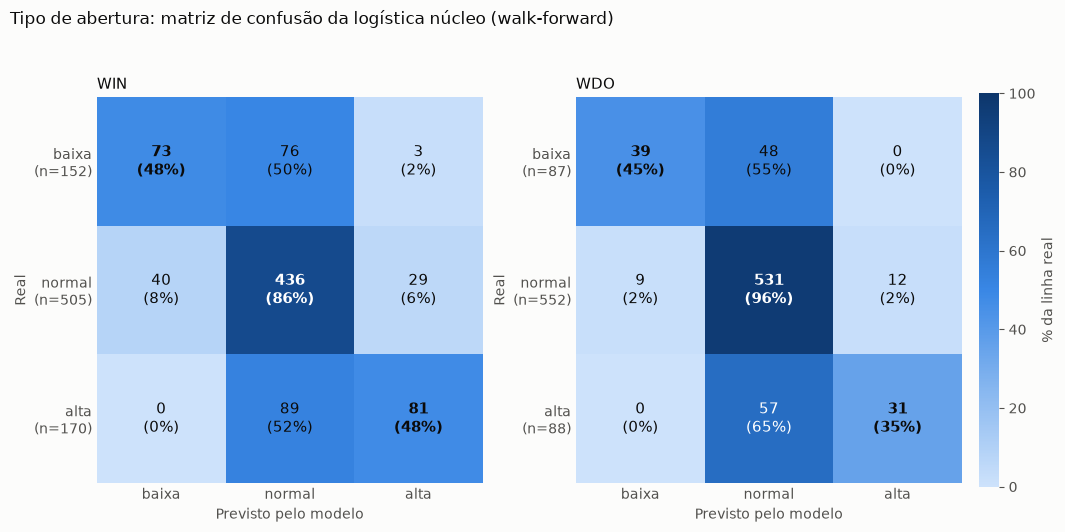

In [10]:
def confusion_figure(results, target, title, path):
    """Duas matrizes lado a lado (WIN e WDO); cor pelo % da linha real."""
    classes_ = CLASSES[target]
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 5.0), constrained_layout=True)
    mats = {}
    for ax, asset in zip(axes, TARGETS):
        counts = confusion(results[asset]["preds"][CONFIG_NAMES[1]], classes_)
        pct = counts.div(counts.sum(axis=1), axis=0).mul(100)
        mats[asset] = (counts, pct)
        image = ax.imshow(pct.to_numpy(), cmap=SEQUENTIAL, vmin=0, vmax=100)
        for i in range(len(classes_)):
            for j in range(len(classes_)):
                ax.text(j, i, f"{counts.iloc[i, j]}\n({pct.iloc[i, j]:.0f}%)", ha="center", va="center", fontsize=11,
                        fontweight="bold" if i == j else "normal", color=ink_on(image.cmap(image.norm(pct.iloc[i, j]))))
        labels = [LABELS[c] for c in classes_]
        ax.set_xticks(range(3), labels)
        ax.set_yticks(range(3), [f"{l}\n(n={int(counts.iloc[k].sum())})" for k, l in enumerate(labels)])
        ax.set_xlabel("Previsto pelo modelo")
        ax.set_ylabel("Real")
        ax.set_title(NAMES[asset], loc="left", fontsize=11)
        ax.tick_params(length=0)
        for spine in ax.spines.values():
            spine.set_visible(False)
    bar = fig.colorbar(image, ax=axes, shrink=0.8, pad=0.02)
    bar.set_label("% da linha real")
    bar.outline.set_visible(False)
    fig.suptitle(title, x=0.0, ha="left", fontsize=12, y=1.06)
    fig.savefig(path, dpi=150, bbox_inches="tight", pad_inches=0.15)
    plt.show()
    return mats

conf1 = confusion_figure(q1, "y_gap_class", "Tipo de abertura: matriz de confusão da logística núcleo (walk-forward)",
                         FIGURES / "06_matriz_gap.png")

## 6. Pergunta 2: o que o preço faz depois da abertura? (`y_behavior`)

Às 09:00 o gap **já aconteceu**: o preço de abertura é conhecido. Então a pergunta que interessa para operar vem depois: nos dias de gap relevante, o preço **segue** (tendência), **volta** (reversão) ou **fica parado** (lateral)?

Aqui as variáveis ficam **alinhadas ao gap**: o retorno overnight de cada ativo é multiplicado pelo sinal do gap. Assim, um valor positivo quer dizer "o ativo andou na mesma direção do gap". Isso usa o gap, então essas colunas se chamam `x_open_aligned_*` e só podem servir para a pergunta 2.

Configurações:

1. **Linha de base:** frequência histórica.
2. **Logística núcleo:** os retornos overnight alinhados, o tamanho do gap (`x_open_gap_abs`) e a faixa média recente do alvo (`x_pre_target_range_5d`, a amplitude dos últimos 5 pregões).
3. **Logística núcleo + todas as `x_pre_`.**

Mesmo cuidado de antes: uma única amostra, comum às três configurações.

In [11]:
ALIGNED = [c.replace("x_pre_", "x_open_aligned_", 1) for c in OVERNIGHT]
CORE_B = ALIGNED + ["x_open_gap_abs", "x_pre_target_range_5d"]
tables_b = {a: add_aligned_features(tables[a], OVERNIGHT) for a in TARGETS}
q2 = {}
for asset in TARGETS:
    q2[asset] = evaluate(tables_b[asset], "y_behavior", CORE_B, ALL_PRE)
    display(Markdown(f"### {NAMES[asset]}: comportamento pós-abertura"))
    display(show_metrics(q2[asset]["metrics"]))
lines = []
for asset in TARGETS:
    start, end = period(q2[asset]["preds"])
    lines.append(f"- **{NAMES[asset]}:** {len(q2[asset]['sample'])} dias na amostra comum "
                 f"({q2[asset]['n_dropped']} dias com rótulo saíram por falta de alguma variável). "
                 f"Teste de {start:%d/%m/%Y} a {end:%d/%m/%Y}, com {int(q2[asset]['metrics'].n.iloc[0])} previsões.")
display(Markdown("\n".join(lines)))

### WIN: comportamento pós-abertura

,n,acerto,acerto_balanceado,log_loss,brier
Linha de base,321,36.4%,33.1%,1.0979,0.6634
Logística núcleo,321,36.1%,33.2%,1.1135,0.6781
Logística núcleo + todas x_pre_,321,38.0%,36.0%,1.4153,0.7982


### WDO: comportamento pós-abertura

,n,acerto,acerto_balanceado,log_loss,brier
Linha de base,175,43.4%,33.3%,1.0738,0.6507
Logística núcleo,175,40.6%,38.3%,1.1167,0.6778
Logística núcleo + todas x_pre_,175,38.9%,36.8%,1.4566,0.7898


- **WIN:** 575 dias na amostra comum (13 dias com rótulo saíram por falta de alguma variável). Teste de 27/10/2022 a 23/09/2026, com 321 previsões.
- **WDO:** 370 dias na amostra comum (13 dias com rótulo saíram por falta de alguma variável). Teste de 26/09/2022 a 01/04/2026, com 175 previsões.

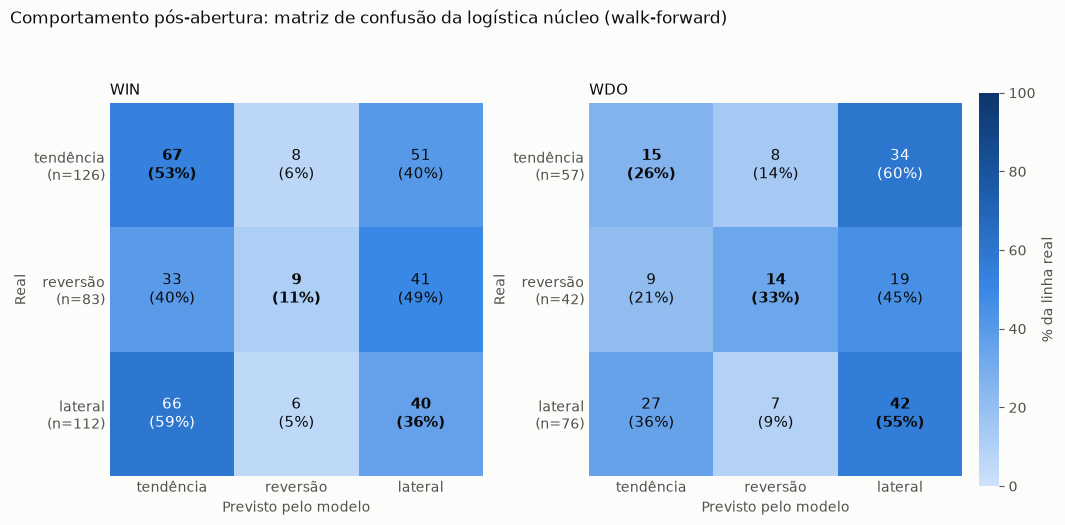

In [12]:
conf2 = confusion_figure(q2, "y_behavior", "Comportamento pós-abertura: matriz de confusão da logística núcleo (walk-forward)", FIGURES / "07_matriz_comportamento.png")

## 7. Conclusões

In [13]:
def verdicts(results, question):
    """Compara o log loss de cada logística com o da linha de base."""
    out, facts = [], {}
    for asset in TARGETS:
        m = results[asset]["metrics"]
        base = m.loc[CONFIG_NAMES[0], "log_loss"]
        for name in CONFIG_NAMES[1:]:
            ll = m.loc[name, "log_loss"]
            better = ll < base
            facts[(asset, name)] = (base, ll, better)
            verdict = "há sinal (log loss menor que o da linha de base)" if better else \
                      "sem sinal (log loss igual ou maior que o da linha de base)"
            out.append(f"- **{NAMES[asset]}, {name}:** log loss {ll:.4f} contra {base:.4f} da linha de base: {verdict}.")
    return out, facts

v1, facts1 = verdicts(q1, "gap")
v2, facts2 = verdicts(q2, "comportamento")
base_acc = lambda r, a: r[a]["metrics"].loc[CONFIG_NAMES[0], "acerto"] * 100
core_acc = lambda r, a: r[a]["metrics"].loc[CONFIG_NAMES[1], "acerto"] * 100
conclusion_text = (
    "**Pergunta 1, tipo de abertura.** Só dizemos que há sinal quando o log loss da logística é menor que o da linha de base.\n\n"
    + "\n".join(v1) + "\n\n"
    f"O acerto da logística núcleo foi {core_acc(q1,'win'):.1f}% no WIN (linha de base {base_acc(q1,'win'):.1f}%) e "
    f"{core_acc(q1,'wdo'):.1f}% no WDO (linha de base {base_acc(q1,'wdo'):.1f}%). Acertar a classe mais comum não prova nada; "
    "olhe o log loss e a diagonal da matriz.\n\n"
    "**Pergunta 2, comportamento depois da abertura.**\n\n" + "\n".join(v2) + "\n\n"
    f"O acerto da logística núcleo foi {core_acc(q2,'win'):.1f}% no WIN (linha de base {base_acc(q2,'win'):.1f}%) e "
    f"{core_acc(q2,'wdo'):.1f}% no WDO (linha de base {base_acc(q2,'wdo'):.1f}%).\n\n"
    "**Acertar o gap não é oportunidade de lucro.** Às 09:00 o gap já aconteceu e não dá para operá-lo. "
    "O que importaria para operar é a pergunta 2: saber se o preço segue, volta ou fica parado depois da abertura.\n\n"
    "**Limites.** Esta é só a primeira avaliação. Não há gradient boosting, não há curva de calibração e não há backtest com "
    "custos e slippage (a diferença entre o preço esperado e o executado). Um log loss menor que o da linha de base ainda não "
    "é uma regra lucrativa."
)
display(Markdown(conclusion_text))

**Pergunta 1, tipo de abertura.** Só dizemos que há sinal quando o log loss da logística é menor que o da linha de base.

- **WIN, Logística núcleo:** log loss 0.6710 contra 0.9647 da linha de base: há sinal (log loss menor que o da linha de base).
- **WIN, Logística núcleo + todas x_pre_:** log loss 0.7363 contra 0.9647 da linha de base: há sinal (log loss menor que o da linha de base).
- **WDO, Logística núcleo:** log loss 0.4933 contra 0.7297 da linha de base: há sinal (log loss menor que o da linha de base).
- **WDO, Logística núcleo + todas x_pre_:** log loss 0.5844 contra 0.7297 da linha de base: há sinal (log loss menor que o da linha de base).

O acerto da logística núcleo foi 71.3% no WIN (linha de base 61.1%) e 82.7% no WDO (linha de base 75.9%). Acertar a classe mais comum não prova nada; olhe o log loss e a diagonal da matriz.

**Pergunta 2, comportamento depois da abertura.**

- **WIN, Logística núcleo:** log loss 1.1135 contra 1.0979 da linha de base: sem sinal (log loss igual ou maior que o da linha de base).
- **WIN, Logística núcleo + todas x_pre_:** log loss 1.4153 contra 1.0979 da linha de base: sem sinal (log loss igual ou maior que o da linha de base).
- **WDO, Logística núcleo:** log loss 1.1167 contra 1.0738 da linha de base: sem sinal (log loss igual ou maior que o da linha de base).
- **WDO, Logística núcleo + todas x_pre_:** log loss 1.4566 contra 1.0738 da linha de base: sem sinal (log loss igual ou maior que o da linha de base).

O acerto da logística núcleo foi 36.1% no WIN (linha de base 36.4%) e 40.6% no WDO (linha de base 43.4%).

**Acertar o gap não é oportunidade de lucro.** Às 09:00 o gap já aconteceu e não dá para operá-lo. O que importaria para operar é a pergunta 2: saber se o preço segue, volta ou fica parado depois da abertura.

**Limites.** Esta é só a primeira avaliação. Não há gradient boosting, não há curva de calibração e não há backtest com custos e slippage (a diferença entre o preço esperado e o executado). Um log loss menor que o da linha de base ainda não é uma regra lucrativa.

## 8. Relatório em arquivo

In [14]:
def md_table(frame: pd.DataFrame, index_name: str = "") -> str:
    """Tabela em Markdown, sem depender de bibliotecas extras."""
    header = "| " + " | ".join([index_name, *map(str, frame.columns)]) + " |"
    rule = "|" + "---|" * (frame.shape[1] + 1)
    body = ["| " + " | ".join([str(i), *map(str, row)]) + " |" for i, row in zip(frame.index, frame.to_numpy())]
    return "\n".join([header, rule, *body])

def confusion_md(mats, target):
    parts = []
    for asset in TARGETS:
        counts, pct = mats[asset]
        cell = counts.astype(str) + " (" + pct.round(0).astype(int).astype(str) + "%)"
        cell.index = [LABELS[i] for i in cell.index]
        cell.columns = [LABELS[c] for c in cell.columns]
        parts.append(f"**{NAMES[asset]}** (linhas = real, colunas = previsto, % da linha real)\n\n" + md_table(cell, "real \\ previsto"))
    return "\n\n".join(parts)

def metrics_md(results):
    return "\n\n".join(f"**{NAMES[a]}**\n\n" + md_table(show_metrics(results[a]["metrics"]), "configuração") for a in TARGETS)

def period_md(results):
    out = []
    for a in TARGETS:
        start, end = period(results[a]["preds"])
        out.append(f"- {NAMES[a]}: {start:%Y-%m-%d} a {end:%Y-%m-%d}, {int(results[a]['metrics'].n.iloc[0])} previsões, "
                   f"amostra comum de {len(results[a]['sample'])} dias.")
    return "\n".join(out)

report = f"""# Correlação e matriz de confusão

Gerado por `notebooks/02_correlacao_e_matriz_confusao.ipynb`. Primeira avaliação: linha de base e regressão logística em walk-forward
(treino {WF['train_years']} anos, teste {WF['test_months']} meses, avanço {WF['step_months']} meses, C = {LOGISTIC_C}).

## Pergunta 1: tipo de abertura (`y_gap_class`)

Período testado:

{period_md(q1)}

{metrics_md(q1)}

Matrizes de confusão da logística núcleo (figura `reports/figures/06_matriz_gap.png`):

{confusion_md(conf1, "y_gap_class")}

## Pergunta 2: comportamento pós-abertura (`y_behavior`, janela de {WINDOW} min)

Período testado:

{period_md(q2)}

{metrics_md(q2)}

Matrizes de confusão da logística núcleo (figura `reports/figures/07_matriz_comportamento.png`):

{confusion_md(conf2, "y_behavior")}

## Correlação

Correlação de Pearson entre o retorno overnight de cada ativo e o gap (figura `reports/figures/05_correlacoes.png`):

{md_table(corr.round(3), "ativo")}

## Conclusões

{conclusion_text}
"""
(ROOT / "reports/correlacao_e_matriz_confusao.md").write_text(report, encoding="utf-8")
display(Markdown(f"Relatório gravado em `reports/correlacao_e_matriz_confusao.md` ({len(report.splitlines())} linhas)."))

Relatório gravado em `reports/correlacao_e_matriz_confusao.md` (130 linhas).